# M4逐步验收（候选版）
在当前目录上传同版bit/hwh与配套文件。关闭其他操作板卡的Notebook和终端脚本。逐格执行，遇到红色报错就停止并保留输出。此Notebook尚未在你的板子上运行。


In [1]:
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from m4_delivery import M4Capture

assert Path('m4.bit').is_file() and Path('m4.hwh').is_file(), '请先上传同名bit和hwh'
RESULT_DIR = 'm4_results_' + datetime.now().strftime('%Y%m%d_%H%M%S')
cap = M4Capture('m4.bit', RESULT_DIR)
print(cap.snapshot())


Candidate protocol detected. SHA256: {'m4.bit': '07a075244eb332556556c6d46d1a7b8523cbdff8fe6a23527fa33addbe832ef8', 'm4.hwh': 'c9721187b8e6aeec91aebb1fda57148ba4c18e395758aef0ec392062ac177f2d'}
{'dmacr': 65538, 'dmasr': 1, 'status_names': ['Halted'], 'length': 0, 'snapshot': 2852126688, 'busy': False, 'overflow': False, 'test_mode': False, 'done': False, 'i2s_live': False, 'cnt_lrclk': 1, 'cnt_beat': 0}


## 1. 先验收DMA和分帧
这一格只检查显式计数器数据，不表示真实音频采集通过。应输出PASS并精确得到0～1023。


In [2]:
counter = cap.capture(test=True, label='counter')
assert np.array_equal(counter, np.arange(1024, dtype=np.uint64))
print('Counter test passed; first/last:', counter[:4], counter[-4:])


counter PASS bytes= 8192 seconds= 0.0202
Counter test passed; first/last: [0 1 2 3] [1020 1021 1022 1023]


## 2. 配置codec并测采样率
新增MCLK输出10MHz，PLL从正确的0x4002地址写入。目标48kHz，实测误差超过1%时停下检查，不手动改为48kHz绕过。


In [4]:
cap.configure_codec()
fs = cap.measure_fs(seconds=2.0)
print('Resolution for next 1024-point FFT:', fs / 1024, 'Hz/bin')


Codec PLL and line-route readback passed. PLL= 0271023c2103
Measured fs estimate: 47998.23 Hz
Resolution for next 1024-point FFT: 46.87327088118604 Hz/bin


## 3. 播放真实测试音
在电脑循环播放随包的pc/test_1kHz.wav，电脑耳机口接板子Audio In，先用较低音量。保持测试音播放后执行下一格。此时结果应为双声道时域数据。


In [5]:
audio_normal = cap.capture(label='audio_normal')
print('shape:', audio_normal.shape, 'dtype:', audio_normal.dtype)
print('RMS:', np.sqrt(np.mean((audio_normal.astype(float) / 2**23)**2, axis=1)))


audio_normal PASS bytes= 8192 seconds= 0.027
shape: (2, 1024) dtype: int32
RMS: [0.08596393 0.08659887]


## 4. 降低电脑音量，再采一帧
保留同一测试音，将电脑音量明显降低，避免完全静音，然后执行下面一格。检查波形/RMS确实响应外部输入变化，排除自检数据被当成音频。


audio_lower PASS bytes= 8192 seconds= 0.0267


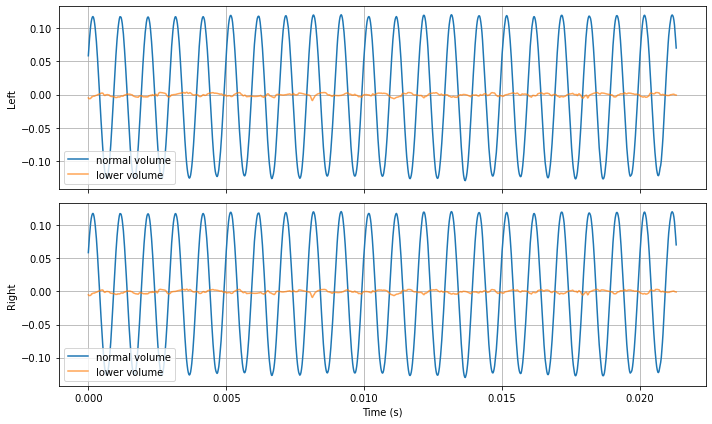

normal RMS: [0.08596393 0.08659887]
lower RMS: [0.00215267 0.00217263]


In [6]:
audio_lower = cap.capture(label='audio_lower')
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
t = np.arange(1024) / fs
for channel, ax in enumerate(axes):
    ax.plot(t, audio_normal[channel] / 2**23, label='normal volume')
    ax.plot(t, audio_lower[channel] / 2**23, label='lower volume', alpha=0.7)
    ax.set_ylabel(['Left', 'Right'][channel]); ax.grid(True); ax.legend()
axes[-1].set_xlabel('Time (s)'); fig.tight_layout()
fig.savefig(cap.output / 'audio_input_check.png', dpi=150)
plt.show()
for name, value in [('normal',audio_normal),('lower',audio_lower)]:
    print(name, 'RMS:', np.sqrt(np.mean((value.astype(float) / 2**23)**2, axis=1)))


## 5. 恢复正常音量，连续10次采集
这里复用同一个Overlay对象；不重新加载bit，检查连续重新武装能否成功。中途任意一次失败都保留日志，修复后重跑本格以完成新的一组10次。


In [7]:
frames = cap.batch(count=10, prefix='cap')
assert len(frames) == 10
print('Ten audio packets passed in the same overlay session.')


cap_01 PASS bytes= 8192 seconds= 0.0276
cap_02 PASS bytes= 8192 seconds= 0.0266
cap_03 PASS bytes= 8192 seconds= 0.0261
cap_04 PASS bytes= 8192 seconds= 0.0262
cap_05 PASS bytes= 8192 seconds= 0.0261
cap_06 PASS bytes= 8192 seconds= 0.0263
cap_07 PASS bytes= 8192 seconds= 0.0266
cap_08 PASS bytes= 8192 seconds= 0.027
cap_09 PASS bytes= 8192 seconds= 0.0261
cap_10 PASS bytes= 8192 seconds= 0.0261
Ten audio packets passed in the same overlay session.


## 6. 软件FFT诊断
这只是检查输入测试音与采样率，不是PL FFT功能。使用随包1kHz音频时保持KNOWN_TONE_HZ=1000。若改用其他已知测试音，填写其真实频率。


Diagnostic peak: 984.3386885049068 Hz; expected: 1000.0


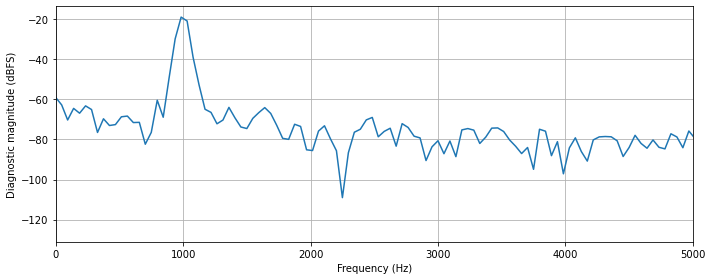

In [8]:
KNOWN_TONE_HZ = 1000.0
channel = int(np.argmax(np.std(frames[0].astype(float), axis=1)))
x = frames[0][channel].astype(float) / 2**23
x -= x.mean()
w = np.hanning(len(x))
mag = np.abs(np.fft.rfft(x * w))
freq = np.fft.rfftfreq(len(x), 1/fs)
k = 1 + int(np.argmax(mag[1:]))
peak_hz = float(freq[k])
print('Diagnostic peak:', peak_hz, 'Hz; expected:', KNOWN_TONE_HZ)
assert abs(peak_hz-KNOWN_TONE_HZ) <= 2*fs/1024, '峰值与测试音不符，请核对输入、采样率和接线'
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(freq, 20*np.log10(2*mag/w.sum()+1e-12))
ax.set(xlabel='Frequency (Hz)', ylabel='Diagnostic magnitude (dBFS)', xlim=(0, min(fs/2,5000)))
ax.grid(True); fig.tight_layout()
fig.savefig(cap.output / 'audio_spectrum_diagnostic.png', dpi=150)
plt.show()


## 7. 打包给B
先确认第4节波形/RMS响应输入音量变化，再把下面变量改为True。打包前需在电脑审查Vivado的timing/clocks/CDC报告并保存本Notebook。生成的M4_for_B.zip在Jupyter当前目录，右键下载。跨包采集存在空隙，FFT下一阶段尚未实现。


In [ ]:
INPUT_CHANGE_CONFIRMED = True
archive = cap.make_handoff(
    input_changed_confirmed=INPUT_CHANGE_CONFIRMED
)
print(archive)